In [96]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, mean, width):
    return 1.0 / (1 + np.exp(width * (x - mean)))

['../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.800000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.71499999999999600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.44999999999999600000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.4200000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.6500000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.5100000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.4700000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos41.5_Xpos41.5800000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_NEv500

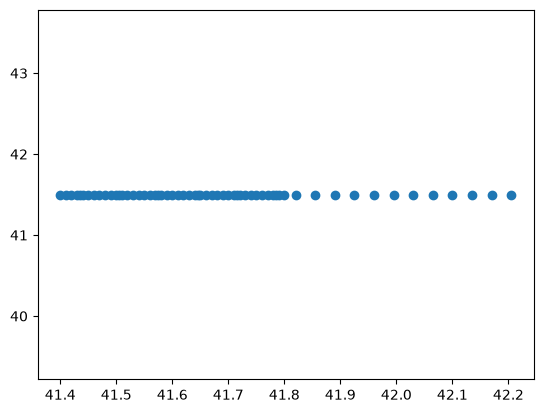

In [97]:
path = "../../Processed_data/"
# path = "../../WiderZRange/"
# path = "../../ZAxisScan/"
# path = "../../PeakAmpWide/"
# path = "/home/daq/LecroyMount/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv1000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")

# files = glob.glob(f"{path}F1--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")
# files = glob.glob(f"{path}F1--AC_LGAD_40um_strip_NEv500_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

print(files)
Z_range = [] # [41.5] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 11)

map_plot_x = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.trc")[0]), 3)
    # z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])        , 3)
    
    x_pos = float(filename.split("Xpos")[1].split("00000.root")[0])
    X_range.append(float(x_pos))
    # x_pos = float(filename.split("Xpos")[1].split("00000.trc")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    Z_range.append(float(z_pos))
    map_plot_x.append(x_pos)
    map_plot_z.append(z_pos)
Z_range = np.unique(Z_range)
# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [98]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    if map_plot_z[f_i] > 50: continue
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_41.5_41.8', 'pos_41.5_41.714999999999996', 'pos_41.5_41.449999999999996', 'pos_41.5_41.42', 'pos_41.5_41.65', 'pos_41.5_41.51', 'pos_41.5_41.47', 'pos_41.5_41.58', 'pos_41.5_41.53', 'pos_41.5_42.065', 'pos_41.5_42.135', 'pos_41.5_42.205', 'pos_41.5_41.779999999999994', 'pos_41.5_41.41', 'pos_41.5_41.589999999999996', 'pos_41.5_41.769999999999996', 'pos_41.5_41.96', 'pos_41.5_41.79', 'pos_41.5_41.68', 'pos_41.5_41.519999999999996', 'pos_41.5_41.574999999999996', 'pos_41.5_41.44', 'pos_41.5_41.785', 'pos_41.5_41.739999999999995', 'pos_41.5_41.599999999999994', 'pos_41.5_41.925', 'pos_41.5_41.73', 'pos_41.5_41.54', 'pos_41.5_41.995', 'pos_41.5_42.169999999999995', 'pos_41.5_42.099999999999994', 'pos_41.5_41.57', 'pos_41.5_41.48', 'pos_41.5_41.72', 'pos_41.5_41.489999999999995', 'pos_41.5_41.4', 'pos_41.5_41.699999999999996', 'pos_41.5_41.559999999999995', 'pos_41.5_41.46', 'pos_41.5_41.644999999999996', 'pos_41.5_41.66', 'pos_41.5_41.43', 'pos_41.5_41.5', 'pos_41.5_41.55',

[41.5]


/tmp/ipykernel_316094/3246547436.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


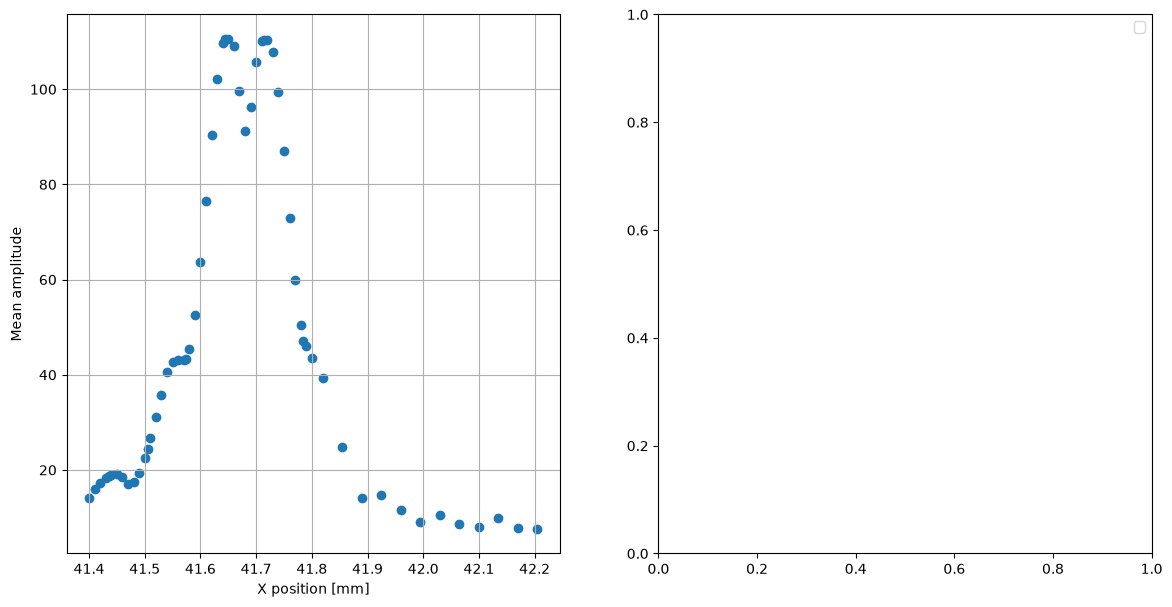

In [101]:
cols = 2
rows = 1
size = 7

strip_index = 0

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
# Z_range = [50.0, 50.8]
print(Z_range)
for z_i, z in enumerate(Z_range):
    mean_amps = []
    n_events = []
    for x_i, x in enumerate(X_range):
        # l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
        l = f"pos_{z}_{x}"
        try:
            # print(z, x)
            mean_amps.append(np.mean(amp[l][:,strip_index]))
            n_events.append(np.sum(timestamps[l][:,strip_index]>0))
            # print(l, mean_amps[-1]) # , n_events[-1])
        except:
            # print(f"{l} is not ready or taken yet")
            mean_amps.append(0)
            n_events.append(0)
    
    sorting = np.argsort(X_range)
    mean_amps = np.array(mean_amps)
    n_events = np.array(n_events)

    # print(X_range[mean_amps != 0])
    # print(mean_amps[mean_amps != 0])

    ax[0].scatter(X_range, mean_amps, label = f"Z position: {z}")
    ax[0].set_xlabel("X position [mm]")
    ax[0].set_ylabel("Mean amplitude")
    # ax[0].set_ylim(5, 30)

    # try:
    # mask = (mean_amps != 0) #  & (mean_amps > 41.4) & (mean_amps < 41.7)
    # print(np.sum(mask))
    # if (np.sum(mask) == 0): continue
    # params = curve_fit(sigmoid, X_range[mask], mean_amps[mask], p0 = (np.mean(X_range), 0.1))
    # print(np.mean(X_range), params[0])
    # sigmoid_y = [sigmoid(i, params[0][0], params[0][1]) for i in X_range]
    # print(sigmoid_y)
    # ax[0].plot(X_range, sigmoid_y, label = f"Z position: {z}")
    # print()

    # ax[1].plot(X_range, n_events, label = f"Z position: {z}")
    # ax[1].set_xlabel("X position [mm]")
    # ax[1].set_ylabel("Number of events")
    ax[0].grid()
    plt.legend()
plt.show()

In [104]:
np.sort(X_range)

array([41.4  , 41.41 , 41.42 , 41.43 , 41.435, 41.44 , 41.45 , 41.46 ,
       41.47 , 41.48 , 41.49 , 41.5  , 41.505, 41.51 , 41.52 , 41.53 ,
       41.54 , 41.55 , 41.56 , 41.57 , 41.575, 41.58 , 41.59 , 41.6  ,
       41.61 , 41.62 , 41.63 , 41.64 , 41.645, 41.65 , 41.66 , 41.67 ,
       41.68 , 41.69 , 41.7  , 41.71 , 41.715, 41.72 , 41.73 , 41.74 ,
       41.75 , 41.76 , 41.77 , 41.78 , 41.785, 41.79 , 41.8  , 41.82 ,
       41.855, 41.89 , 41.925, 41.96 , 41.995, 42.03 , 42.065, 42.1  ,
       42.135, 42.17 , 42.205])